# What drove chance creation at the 2022 World Cup

Reproduces every number and figure in the README, top to bottom from a clean clone. The first run
downloads about 230k events from StatsBomb open data and caches them in `data/`.

Extra time is included in every match; penalty shootouts are excluded. The model explains
**non-penalty xG**; penalty xG is always reported next to it, never mixed in.

In [1]:
import sys; sys.path.insert(0, "../src")
import pandas as pd
import data, metrics as M, model, final, plots
pd.set_option("display.precision", 2, "display.width", 160)

## Data: one row per team per match

In [2]:
ev = M.prepare(data.events())
fid = data.final_match_id()
tm = M.team_match_table(ev, data.matches())      # periods 1-4: extra time in, shootouts out
base, fin = tm[tm.match_id != fid], tm[tm.match_id == fid]
print(f"{ev.match_id.nunique()} matches, {len(ev):,} events -> {len(base)} team-match rows before the final")
print("matches that went to extra time:", int((tm.groupby('match_id').minutes.first() > 110).sum()))

64 matches, 234,637 events -> 126 team-match rows before the final
matches that went to extra time: 7


**Sanity checks:** goals per team match the shot data, and the final reads 3–3.

In [3]:
goals = ev[(ev.period < 5) & (ev.type == "Shot") & (ev.shot_outcome == "Goal")].groupby(["match_id", "team"]).size()
chk = tm.set_index(["match_id", "team"]).goals
print("goals match shot data for every team-match:", (chk == goals.reindex(chk.index, fill_value=0)).all())
fin[["team", "goals", "xg", "pen_xg", "minutes"]]

goals match shot data for every team-match: True


,team,goals,xg,pen_xg,minutes
126,Argentina,3,2.76,0.78,141.41
127,France,3,2.27,1.57,141.41


In [4]:
tm[tm.team.isin(["Argentina", "France"])][["team", "stage", "opponent", "goals", "xg", "pen_xg", "minutes"]]

,team,stage,opponent,goals,xg,pen_xg,minutes
50,France,Group Stage,Australia,4,3.17,0.00,103.47
92,Argentina,Group Stage,Saudi Arabia,1,2.49,0.78,110.22
24,France,Group Stage,Denmark,2,1.93,0.00,100.22
70,Argentina,Group Stage,Mexico,2,0.33,0.00,101.97
21,Argentina,Group Stage,Poland,2,3.08,0.78,99.10
43,France,Group Stage,Tunisia,0,0.48,0.00,104.97
100,Argentina,Round of 16,Australia,2,1.48,0.00,99.44
102,France,Round of 16,Poland,3,1.13,0.00,101.31
113,Argentina,Quarter-finals,Netherlands,2,1.94,0.78,139.85
115,France,Quarter-finals,England,2,0.84,0.00,105.38


The 12 style metrics. None use shots or xG:

In [5]:
pd.DataFrame(M.METRICS, index=["pillar", "definition"]).T

,pillar,definition
possession_share,Build-up,Share of all passes in the match made by the team
passes_per_possession,Build-up,Open-play passes per team possession
pass_completion_under_pressure,Build-up,Completion rate of open-play passes made under...
progressive_passes_p90,Progression,Completed open-play passes that cut the distan...
progressive_carries_p90,Progression,Carries of 5+ units that cut the distance to g...
directness,Progression,Average forward gain (x) per open-play pass
long_ball_share,Progression,Share of open-play passes of 35+ units
field_tilt,Territory,Team share of both teams' passes made in the f...
crosses_per_entry,Territory,Open-play crosses per final-third entry
pressures_per_opp_possession,Pressing,Pressures per opponent possession


## Stage 1: what went with more chances

In [6]:
b = model.fit(base)
print("variance captured by 5 components:", round(b.explained.sum(), 2))
print("R²:", round(b.ols.rsquared, 3), "| average non-penalty xG/90:", round(b.ols.params['const'], 2),
      "| average penalty xG/90:", round(b.mean_pen_p90, 2))
b.effects.rename(index=model.NAMES).round(3)

variance captured by 5 components: 0.85
R²: 0.359 | average non-penalty xG/90: 0.94 | average penalty xG/90: 0.11


,effect,lo,hi,p
Control,0.26,0.16,0.36,0.00e+00
Direct & wide,0.21,0.10,0.31,0.00e+00
Pressing volume,0.13,0.01,0.25,3.20e-02
Pressing height,-0.02,-0.12,0.07,6.78e-01
Ball-carrying,0.17,0.06,0.27,2.00e-03


What each component is made of (PCA loadings):

In [7]:
b.loadings.rename(columns=model.NAMES).round(2)

,Control,Direct & wide,Pressing volume,Pressing height,Ball-carrying
possession_share,0.37,0.05,-0.11,-0.13,-0.09
passes_per_possession,0.35,-0.16,0.05,-0.05,0.15
pass_completion_under_pressure,0.24,-0.28,0.32,-0.37,-0.50
progressive_passes_p90,0.33,0.26,0.02,0.06,0.15
progressive_carries_p90,0.25,0.21,0.31,-0.19,0.67
directness,-0.33,0.34,-0.04,0.20,0.03
long_ball_share,-0.32,0.29,0.06,0.02,-0.15
field_tilt,0.38,0.16,-0.04,0.12,-0.11
crosses_per_entry,-0.11,0.51,0.47,-0.42,-0.26
pressures_per_opp_possession,-0.10,-0.30,0.74,0.49,0.09


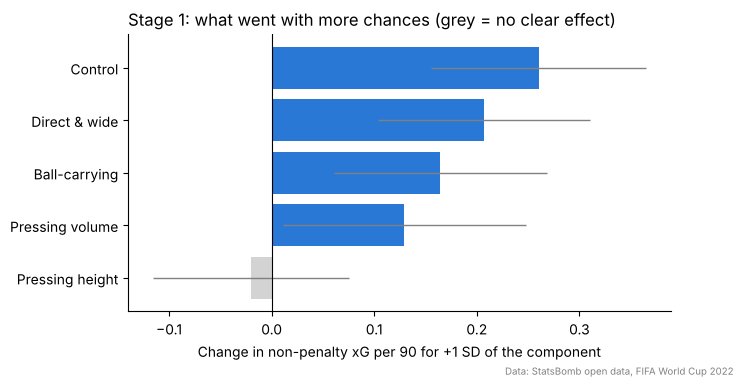

In [8]:
plots.drivers(b);

## Stage 2: the finalists before the final

In [9]:
usual = b.components(base).join(base.team).groupby("team").mean()
ranks = usual.rank(ascending=False).astype(int).rename(columns=model.NAMES)
before = b.summary(base).join(base.team).groupby("team").mean()
ranks["actual xG (incl. pens)"] = (before.non_penalty + before.penalties).rank(ascending=False).astype(int)
ranks["predicted from style"] = before.predicted.rank(ascending=False).astype(int)
print("Ranks among 32 teams (1 = highest):")
display(ranks.loc[["Argentina", "France"]].T)
before.loc[["Argentina", "France"]]

Ranks among 32 teams (1 = highest):


team,Argentina,France
Control,6,12
Direct & wide,31,21
Pressing volume,5,13
Pressing height,18,28
Ball-carrying,3,1
actual xG (incl. pens),3,5
predicted from style,6,4


,predicted,non_penalty,penalties
team,,,
Argentina,1.11,1.14,0.43
France,1.19,1.41,0.00


## Stage 3: the final (all 120 minutes)

In [10]:
in_final = b.summary(fin, totals=True).set_index(fin.team)
in_final

,predicted,non_penalty,penalties
team,,,
Argentina,1.91,1.97,0.78
France,1.11,0.71,1.57


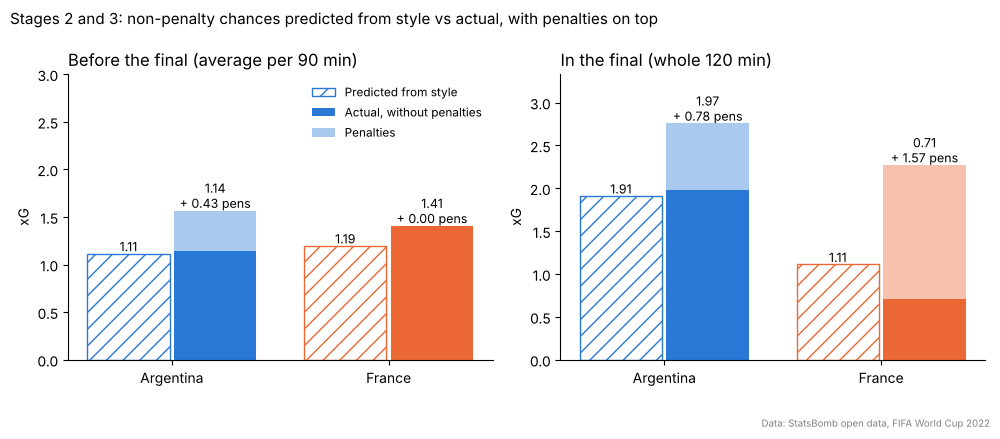

In [11]:
plots.predicted_vs_actual(before, in_final);

In [12]:
fin_comp = b.components(fin).set_index(fin.team)
pd.concat({"usual": usual.loc[["Argentina", "France"]], "final": fin_comp}, axis=1).rename(columns=model.NAMES, level=1).T

team                   Argentina  France
usual Control               1.72    0.61
      Direct & wide        -0.97   -0.14
      Pressing volume       0.45    0.10
      Pressing height      -0.05   -0.41
      Ball-carrying         0.47    0.97
final Control               0.02   -0.98
      Direct & wide         1.15   -0.91
      Pressing volume      -0.60    0.02
      Pressing height      -0.60    0.66
      Ball-carrying         0.76    0.17

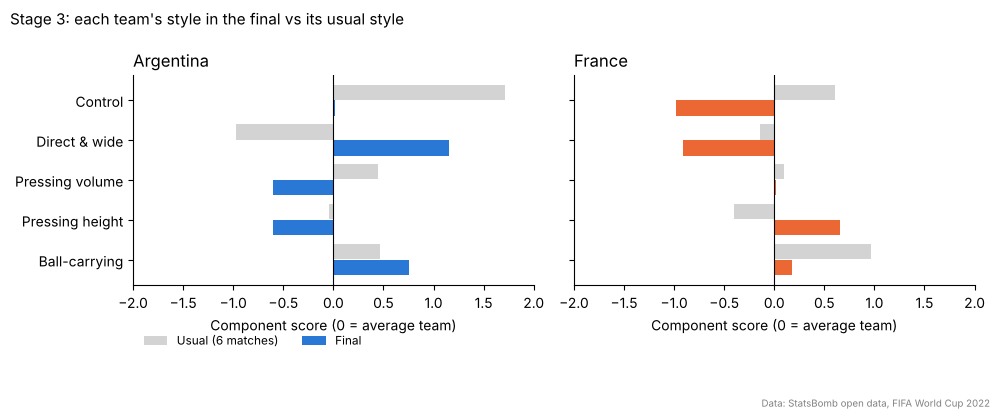

In [13]:
plots.style_shift(usual, fin_comp);

Goals and substitutions straight from the event data:

In [14]:
fe = ev[ev.match_id == fid]
display(final.goals(fe))
final.substitutions(fe)

,period,minute,second,team,player,shot_type
103561,1,22,24,Argentina,Lionel Andrés Messi Cuccittini,Penalty
103563,1,35,22,Argentina,Ángel Fabián Di María Hernández,Open Play
103570,2,79,24,France,Kylian Mbappé Lottin,Penalty
103571,2,80,59,France,Kylian Mbappé Lottin,Open Play
103583,4,107,58,Argentina,Lionel Andrés Messi Cuccittini,Open Play
103585,4,117,5,France,Kylian Mbappé Lottin,Penalty


,period,minute,second,team,player,substitution_replacement,substitution_outcome
103717,1,40,32,France,Ousmane Dembélé,Randal Kolo Muani,Tactical
103718,1,41,1,France,Olivier Giroud,Marcus Thuram,Tactical
103719,2,63,51,Argentina,Ángel Fabián Di María Hernández,Marcos Javier Acuña,Tactical
103720,2,70,27,France,Theo Bernard François Hernández,Eduardo Camavinga,Tactical
103721,2,70,29,France,Antoine Griezmann,Kingsley Coman,Tactical
103722,3,90,0,Argentina,Nahuel Molina Lucero,Gonzalo Ariel Montiel,Tactical
103723,3,95,10,France,Adrien Rabiot,Youssouf Fofana,Tactical
103724,3,101,37,Argentina,Rodrigo Javier De Paul,Leandro Daniel Paredes,Tactical
103725,3,101,49,Argentina,Julián Álvarez,Lautaro Javier Martínez,Tactical
103726,4,112,28,France,Raphaël Varane,Ibrahima Konaté,Injury


                    sum  count
team      penalty             
Argentina False    1.97     19
          True     0.78      1
France    False    0.71      8
          True     1.57      2


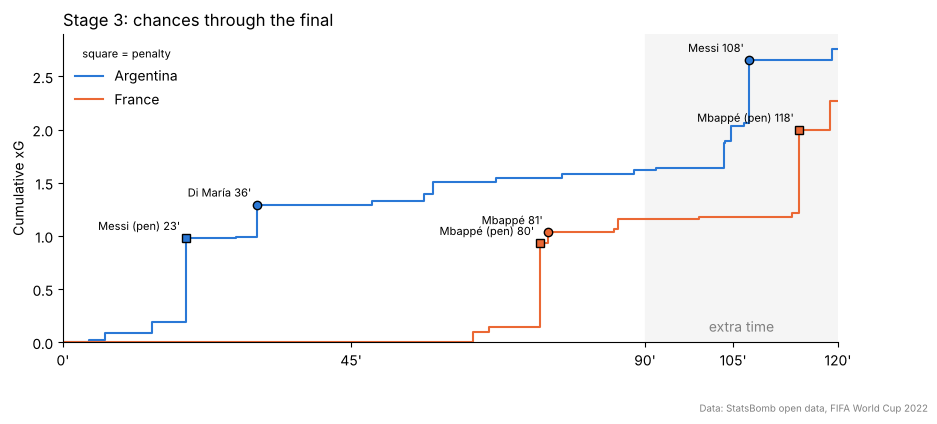

In [15]:
shots, subs, starts = final.xg_timeline(fe)
print(shots.groupby(["team", "penalty"]).xg.agg(["sum", "count"]))
plots.xg_timeline(shots, subs, starts);

The final by score state (raw xG next to rates, because the windows are short):

In [16]:
final.by_window(fe)[["minutes", "xg", "xg_p90", "possession_share", "pressure_height", "progressive_carries_p90"]]

minutes    xg  xg_p90  possession_share  pressure_height  progressive_carries_p90
window               team                                                                                        
0–22'\n0–0           Argentina    20.90  0.19    0.84              0.59            54.57                    12.92
                     France       20.90  0.00    0.00              0.41            52.01                     8.61
22–79'\nARG lead     Argentina    63.40  1.35    1.92              0.51            54.98                    17.04
                     France       63.40  0.15    0.21              0.49            57.95                    17.04
79–90'\nFRA comeback Argentina    19.22  0.07    0.34              0.50            38.15                     9.37
                     France       19.22  1.01    4.74              0.50            64.56                    28.10
91–120'\nextra time  Argentina    35.20  1.14    2.91              0.63            50.76                    15.34
                     France       35.20  1.11    2.85              0.37            50.71                     7.67

## Checks against public analysis of the tournament and the final

Claims from match reports and tactical reviews, checked against the StatsBomb data.

In [17]:
s = fe[fe.type == "Shot"]
print("Shots by period (1-2 = halves, 3-4 = extra time, 5 = shootout):")
display(s.groupby(["period", "team"]).size().unstack(fill_value=0))
npx = s[(s.period <= 4) & (s.shot_type != "Penalty")]
print("Non-penalty xG at 90':", npx[npx.period <= 2].groupby("team").shot_statsbomb_xg.sum().round(2).to_dict())
print("Non-penalty xG in extra time:", npx[npx.period >= 3].groupby("team").shot_statsbomb_xg.sum().round(2).to_dict())
print("Penalties won by:", fe[fe.foul_won_penalty == True][["minute", "team", "player"]].values.tolist())
goals_kp = s[(s.shot_outcome == "Goal") & s.shot_key_pass_id.notna() & (s.period < 5)]
print("Assists:", [(fe.set_index("id").loc[k, "player"], m) for k, m in zip(goals_kp.shot_key_pass_id, goals_kp.minute)])
a = npx[(npx.team == "Argentina") & (npx.period <= 2)]
t = a.minute + a.second / 60
print("Argentina non-penalty xG with Di María on (0-64'):", round(a[t < 63.85].shot_statsbomb_xg.sum(), 2),
      "| after he went off (64-90'):", round(a[t >= 63.85].shot_statsbomb_xg.sum(), 2))

Shots by period (1-2 = halves, 3-4 = extra time, 5 = shootout):


team,Argentina,France
period,,
1,6,0
2,6,6
3,4,1
4,4,3
5,4,4


Non-penalty xG at 90': {'Argentina': 0.84, 'France': 0.37}
Non-penalty xG in extra time: {'Argentina': 1.14, 'France': 0.33}
Penalties won by: [[20, 'Argentina', 'Ángel Fabián Di María Hernández'], [78, 'France', 'Randal Kolo Muani']]
Assists: [('Alexis Mac Allister', 35), ('Marcus Thuram', 80)]
Argentina non-penalty xG with Di María on (0-64'): 0.72 | after he went off (64-90'): 0.11


Possession and winning across the tournament (team-matches before the final):

In [18]:
import numpy as np
x = base.set_index(["match_id", "team"])
opp = x.loc[list(zip(base.match_id, base.opponent))]
pts = np.select([base.goals.values > opp.goals.values, base.goals.values == opp.goals.values], [3, 1], 0)
print("possession vs non-penalty xG:", round(np.corrcoef(base.possession_share, base.npxg_p90)[0, 1], 2))
print("possession vs points:", round(np.corrcoef(base.possession_share, pts)[0, 1], 2))
sp = b.summary(base).join(base.team).groupby("team").mean().loc["Spain"]
print("Spain, non-penalty xG per 90: predicted", round(sp.predicted, 2), "actual", round(sp.non_penalty, 2))

possession vs non-penalty xG: 0.31
possession vs points: -0.08
Spain, non-penalty xG per 90: predicted 1.17 actual 0.86
